In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm

In [8]:
df = pd.read_csv('./datasets/Titanic-Dataset.csv')
df = df.dropna(subset=['Age'])

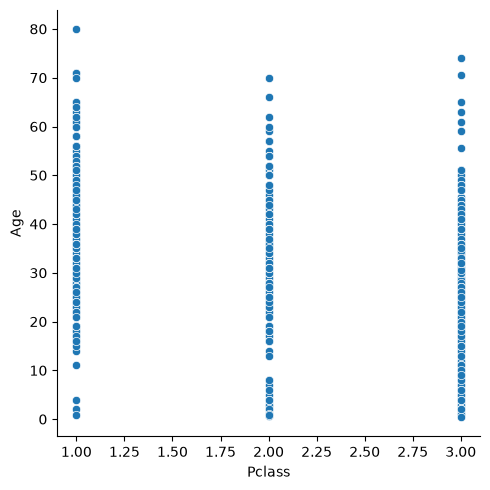

In [9]:
sns.relplot(x='Pclass', y='Age', kind='scatter', data=df)
plt.show()

In [10]:
# Databehandling / "Data wrangling"
#df['Age'] = df['Age'].fillna(df['Age'].median()) # Sett inn median alder, der alder mangler
#df = df.dropna(subset=['Age'])  # Evt fjern de som mangler alder?

# Raden 'sex' har verdiene male, eller female. "Mapper" veridene om til tall, slik at dataen kan behandles.
df['Sex_'] = df['Sex'].map({'male': 0, 'female': 1}) 

# Regner ut familiestørrelse ved å slå sammen antall barn/ektefelle og foreldre/barn
df['FamilySize'] = df['SibSp'] + df['Parch']

formel = 'Age ~ Pclass + SibSp + Parch + Sex_'
modell = smf.ols(formel, data=df)
resultat = modell.fit()

print(resultat.summary())

                            OLS Regression Results                            
Dep. Variable:                    Age   R-squared:                       0.234
Model:                            OLS   Adj. R-squared:                  0.230
Method:                 Least Squares   F-statistic:                     54.16
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           7.44e-40
Time:                        20:18:34   Log-Likelihood:                -2828.1
No. Observations:                 714   AIC:                             5666.
Df Residuals:                     709   BIC:                             5689.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     47.6049      1.478     32.199      0.0

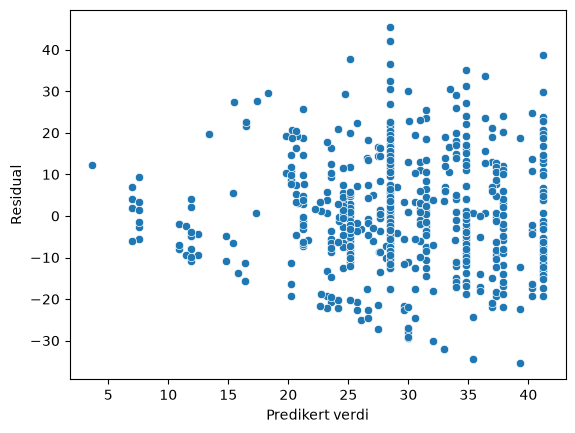

In [11]:
sns.scatterplot(x=resultat.fittedvalues, y=resultat.resid)
plt.ylabel("Residual")
plt.xlabel("Predikert verdi")
plt.show()

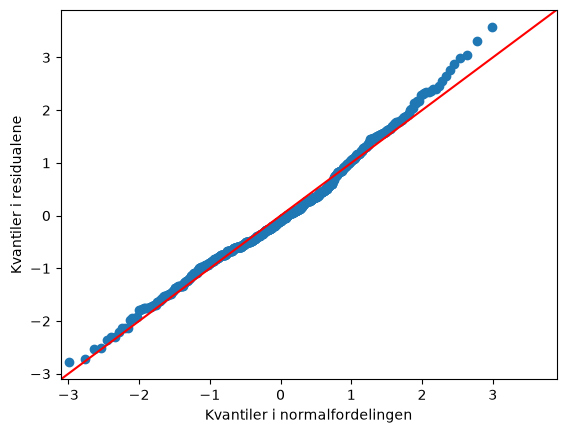

In [12]:
sm.qqplot(resultat.resid, line='45', fit=True)
plt.ylabel("Kvantiler i residualene")
plt.xlabel("Kvantiler i normalfordelingen")
plt.show()